# 03 — Machine-learning cross-check

Part 4. Owner: Tommy. Depends on Part 3 (`02_core_model.ipynb`).

**Question.** Part 3 fits a linear, additive conditional logit. Three things could
be wrong with it, and each is an empirical question rather than a matter of taste:

1. the relationship could be non-linear — a *dealbreaker* cut-off rather than a slope;
2. attributes could interact — "fun only counts if they're also attractive";
3. a flexible model might simply predict better, which would mean the linear
   model is leaving signal on the table.

A gradient booster can capture all three. So we let it try to beat Part 3, and
report what happens. This section is a falsification attempt, not a second
headline.

**Sample.** The union of Part 3's two retained samples (6,222 decisions, 452
people), with ratings standardised using Part 3's own within-gender means and
SDs. `prepare_ml_frame` asserts both against the published Part 3 tables, so this
notebook cannot silently analyse a different sample.

**Cross-validation** groups by `iid`: a held-out person never appears in
training. A row-level split would leak, because a person's other dates carry
their own selectivity.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from src import ml_model

pd.set_option("display.width", 140)
analysis = ml_model.run_analysis()
frame = analysis["frame"]
print(f"{len(frame):,} decisions from {frame['iid'].nunique()} people")

/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packag

/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packag

/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packag

/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packag

/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packag

/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packag

/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept


/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept


/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NU

6,222 decisions from 452 people


/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/private/tmp/claude-501/-Users-tommy2131-Desktop-school-doc-NUS/8fc5ecd5-317a-4c57-9b3b-3ee388dc3340/scratchpad/.venv-ml/lib/python3.9/site-packag

## 1. Does a flexible model beat the linear one?

Grouped 5-fold CV by participant, AUC. `person-demeaned` subtracts each person's
own mean rating first, which is the feature-space analogue of the fixed effect.

In [2]:
analysis["auc"].style.format({
    "logistic_auc": "{:.4f}", "logistic_sd": "{:.4f}", "gbm_auc": "{:.4f}",
    "gbm_sd": "{:.4f}", "gbm_minus_logistic": "{:+.4f}"}).hide(axis="index")

sample,features,n_rows,n_people,logistic_auc,logistic_sd,gbm_auc,gbm_sd,gbm_minus_logistic
Women,standardised,3000,223,0.8153,0.0365,0.7969,0.0347,-0.0185
Women,person-demeaned,3000,223,0.8344,0.0146,0.8115,0.0251,-0.0229
Men,standardised,3222,229,0.8353,0.0132,0.8294,0.0104,-0.0060
Men,person-demeaned,3222,229,0.8365,0.0035,0.8292,0.0180,-0.0073
Pooled,standardised,6222,452,0.8221,0.0150,0.8151,0.0158,-0.0070
Pooled,person-demeaned,6222,452,0.8336,0.0068,0.8241,0.0135,-0.0094


**No.** The booster loses in all six configurations, by 0.006 to 0.023 AUC.
Six ratings entering linearly is the right functional form, so Part 3's
specification is not costing us predictive accuracy.

Demeaning *helps* both models, which is the same point the fixed effects make:
how a partner compares to that person's own average matters more than the
absolute rating.

## 2. Where the models disagree

Three estimates of relative importance, all on the project's convention
(`100 * max(coef, 0) / sum of positives`):

- **conditional logit** — Part 3's published shares, person fixed effects;
- **pooled logit** — identical features, fixed effects dropped;
- **GBM permutation** — out-of-fold AUC drop when one feature is shuffled.

In [3]:
analysis["importance"].style.format({
    "conditional_logit": "{:.2f}", "pooled_logit": "{:.2f}",
    "gbm_permutation": "{:.2f}", "conditional_coef_std": "{:+.3f}",
    "pooled_coef_std": "{:+.3f}",
    "coef_shift_pooled_minus_conditional": "{:+.3f}"}).hide(axis="index")

gender,attribute,label,conditional_logit,pooled_logit,gbm_permutation,conditional_coef_std,pooled_coef_std,coef_shift_pooled_minus_conditional
Women,attr,Attractive,37.86,39.46,43.38,+1.602,+0.859,-0.742
Women,sinc,Sincere,9.18,0.00,6.66,+0.388,-0.219,-0.608
Women,intel,Intelligent,9.37,6.16,1.87,+0.397,+0.134,-0.262
Women,fun,Fun,19.80,26.41,18.93,+0.838,+0.575,-0.263
Women,amb,Ambitious,1.38,0.00,3.11,+0.058,-0.246,-0.304
Women,shar,Shared interests,22.41,27.98,26.06,+0.948,+0.609,-0.339
Men,attr,Attractive,47.37,53.35,66.60,+1.904,+1.249,-0.654
Men,sinc,Sincere,2.19,0.00,1.93,+0.088,-0.208,-0.296
Men,intel,Intelligent,6.03,0.00,2.87,+0.242,-0.042,-0.284
Men,fun,Fun,24.03,24.34,13.32,+0.966,+0.570,-0.396


In [4]:
analysis["agreement"].style.format({
    "spearman_gbm_vs_pooled": "{:.3f}",
    "spearman_gbm_vs_conditional": "{:.3f}",
    "spearman_pooled_vs_conditional": "{:.3f}"}).hide(axis="index")

gender,spearman_gbm_vs_pooled,spearman_gbm_vs_conditional,spearman_pooled_vs_conditional
Women,0.812,0.829,0.986
Men,0.880,0.943,0.941


**The ranking is robust; the estimates behind it are not.**

All three methods put attractiveness first and ambition last, and rank agreement
with the fixed-effects model is 0.83 (women) and 0.94 (men). That is reassuring
for the headline.

But look at the signed coefficients. **Every one of the twelve shrinks toward
zero when the person effect is dropped**, by 0.21 to 0.74 standard deviations,
and four cross below zero — women's sincerity and ambition, men's sincerity and
intelligence. Because the agreed importance rule clips negatives to zero, the
pooled model reports those as exactly `0.00`, which reads as "no effect" when it
actually means "estimated negative".

So the fixed effects are load-bearing rather than decorative: without them the
trade-offs are attenuated, because a generous rater's high ratings get compared
against other people's decisions instead of their own.

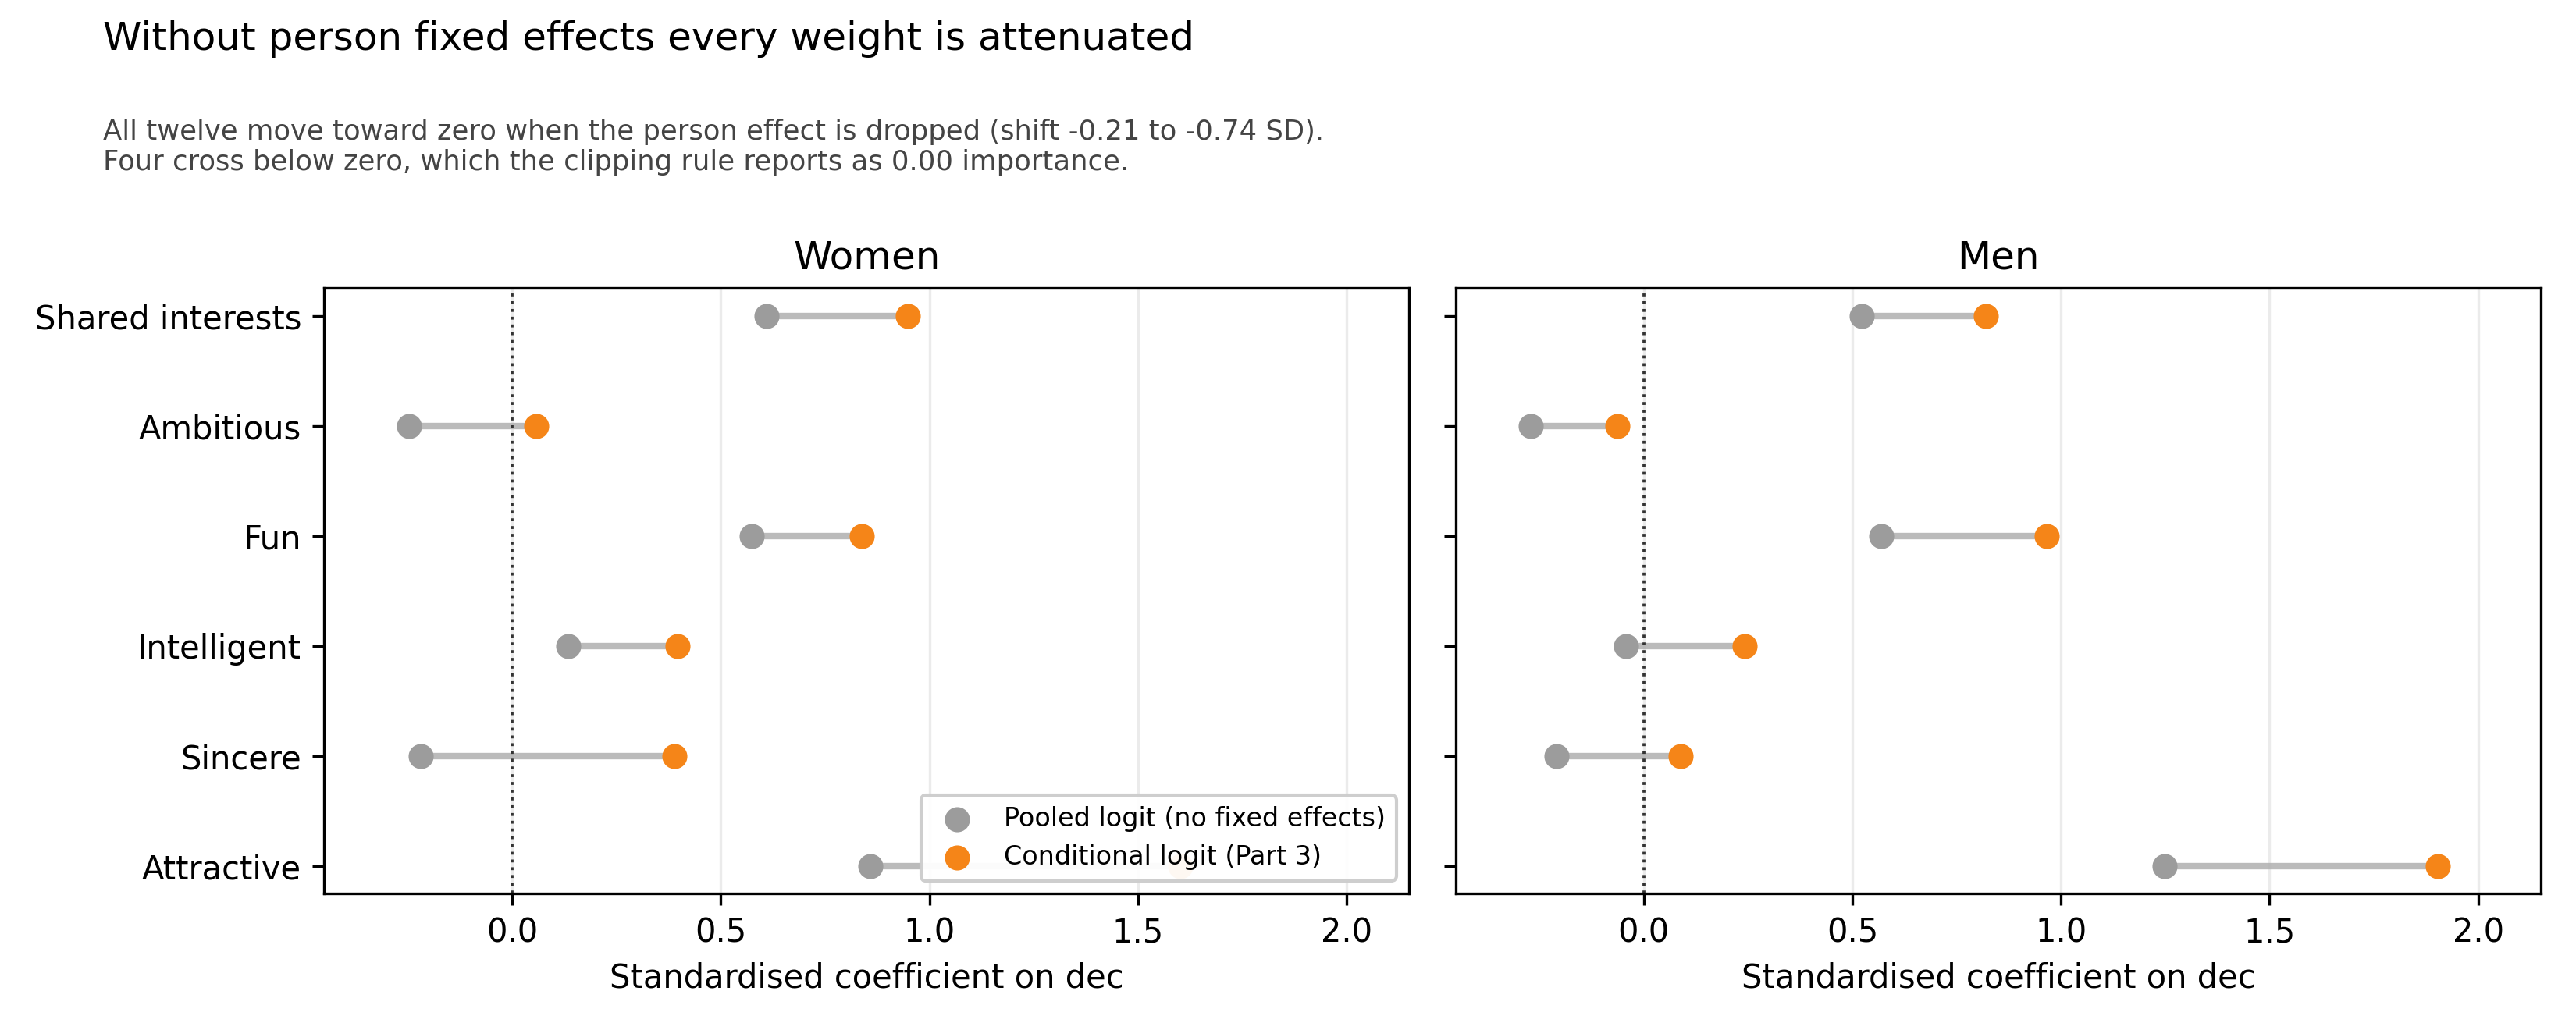

In [5]:
from IPython.display import Image
Image(str(ROOT / "outputs/figures/ml_fixed_effect_shift.png"))

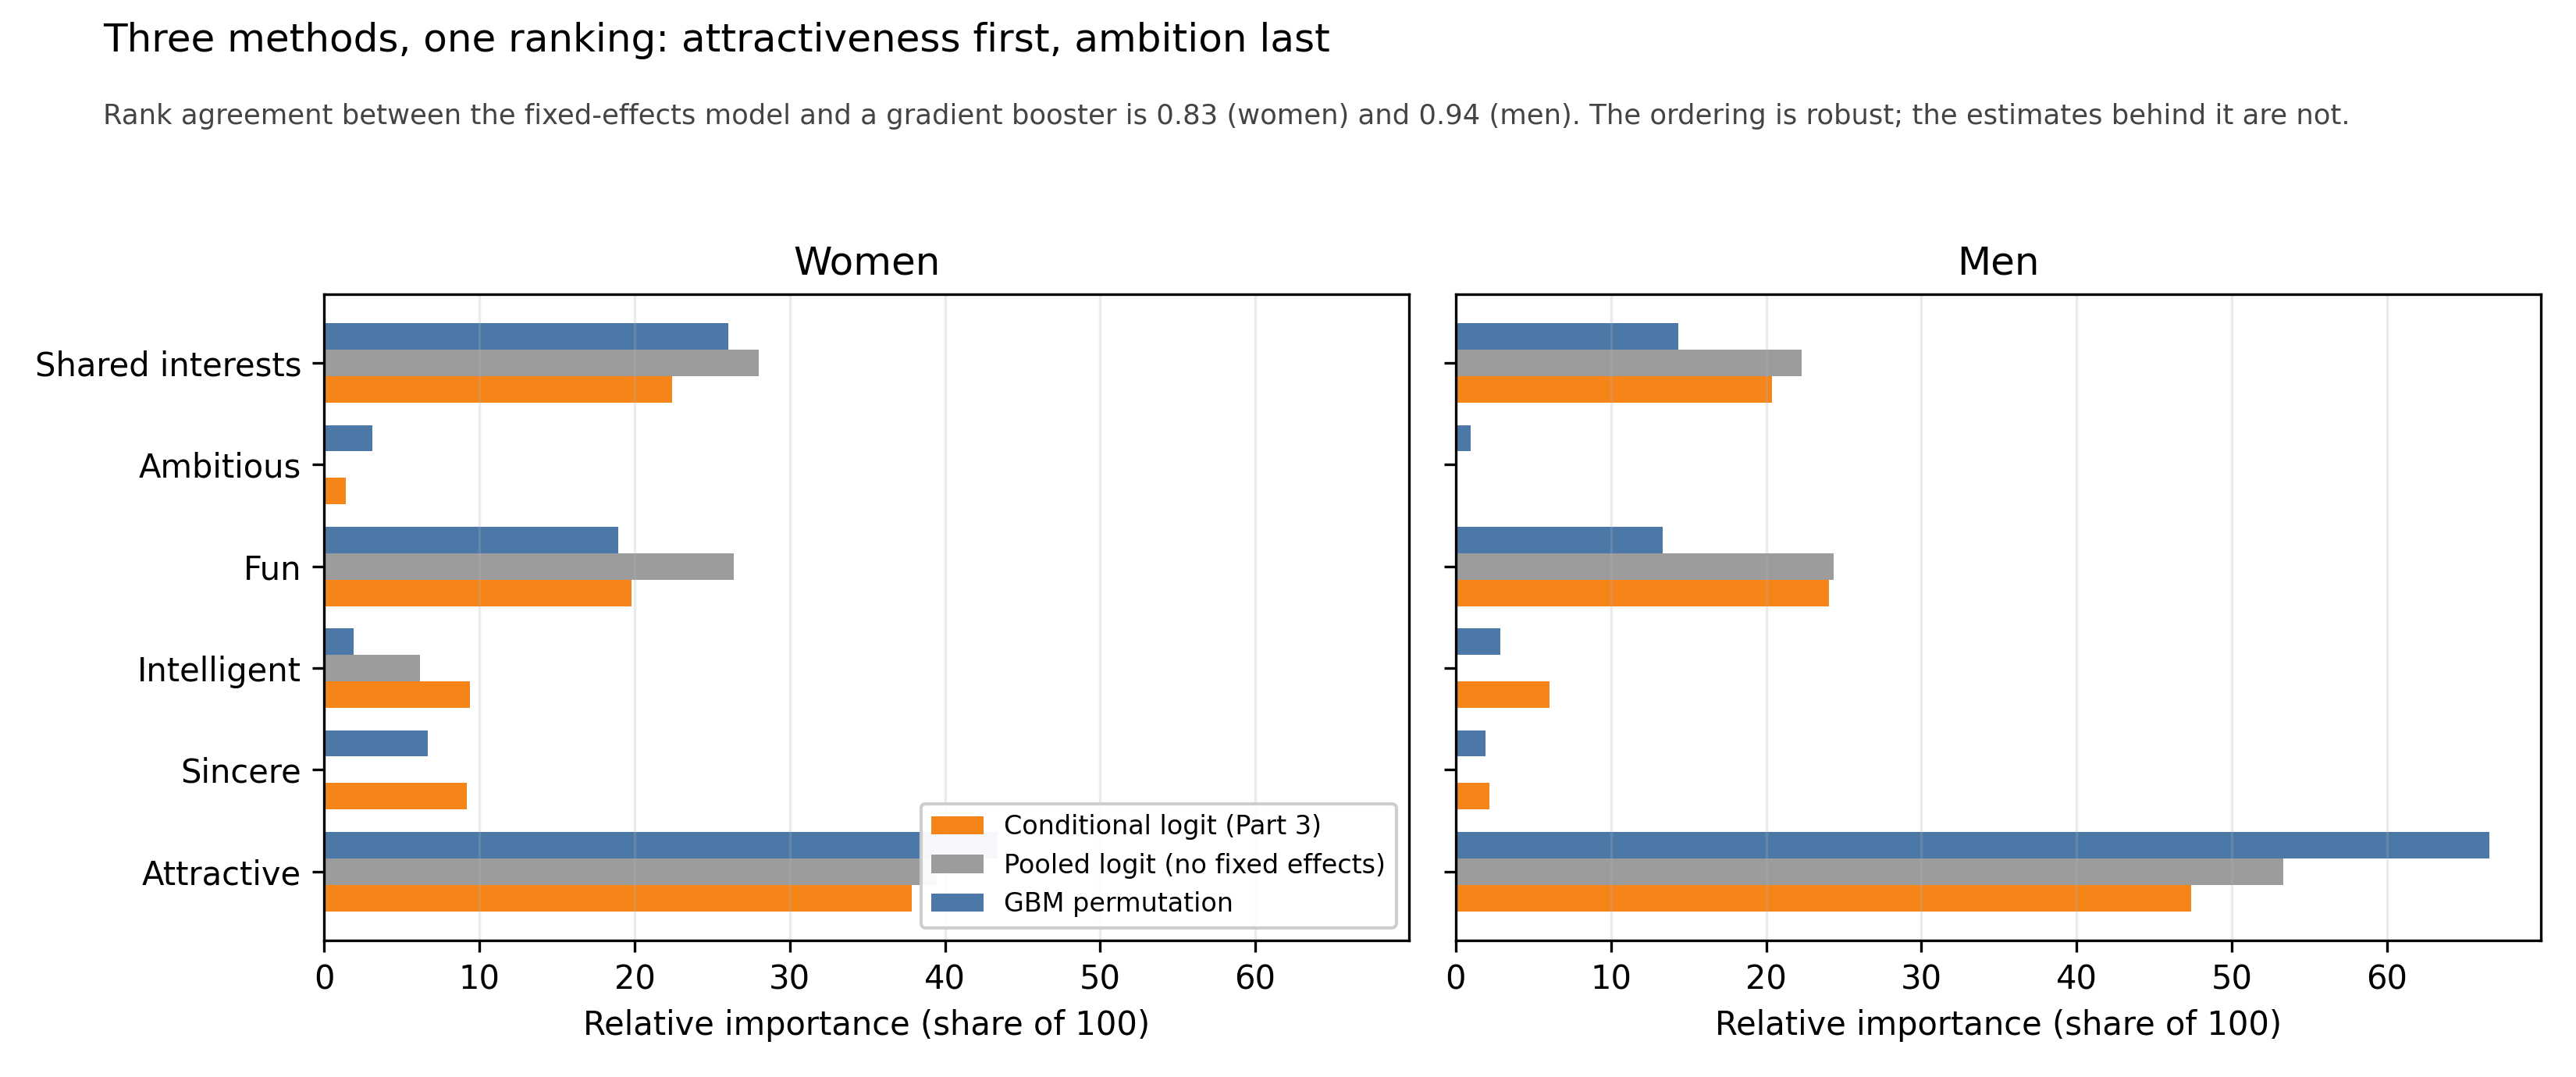

In [6]:
Image(str(ROOT / "outputs/figures/ml_importance_comparison.png"))

## 3. Is there a dealbreaker threshold?

If people screened on attractiveness — "below 6 is an automatic no" — P(yes)
would jump at a cut-off, and a model with one free parameter per rating level
would beat a single slope.

In [7]:
analysis["curve"].style.format({
    "observed_p_yes": "{:.3f}", "gbm_fitted": "{:.3f}"}).hide(axis="index")

attr,n,observed_p_yes,gbm_fitted
1,71,0.056,0.061
2,173,0.064,0.063
3,275,0.062,0.061
4,564,0.113,0.114
5,930,0.208,0.208
6,1288,0.357,0.357
7,1281,0.559,0.559
8,974,0.747,0.747
9,424,0.790,0.789
10,242,0.847,0.848


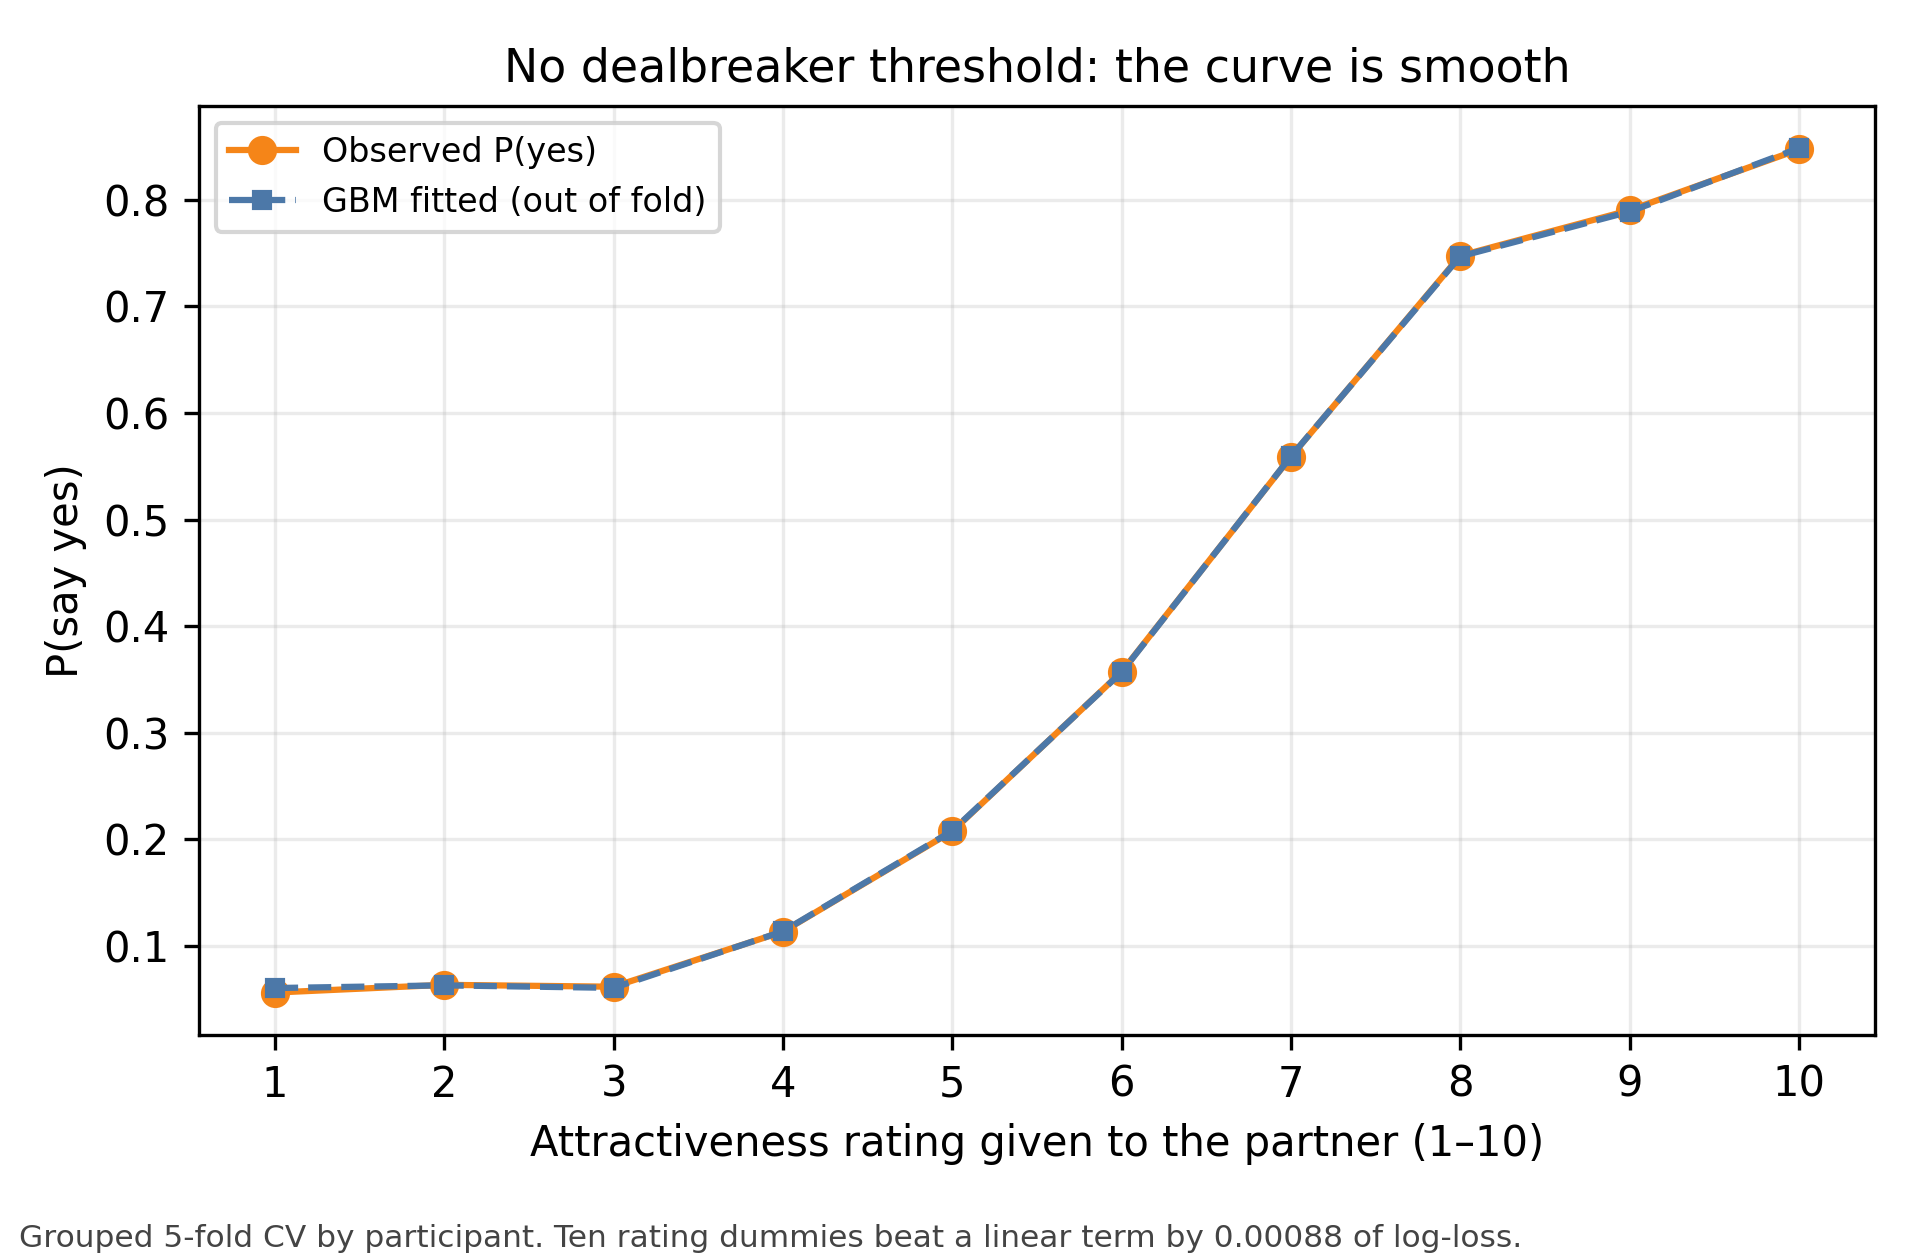

In [8]:
Image(str(ROOT / "outputs/figures/ml_attractiveness_curve.png"))

In [9]:
print(json.dumps(analysis["diagnostics"]["threshold"], indent=2))
print(json.dumps(analysis["diagnostics"]["interactions"], indent=2))

{
  "log_loss_linear": 0.5475314092814115,
  "log_loss_dummies": 0.546650868954744,
  "improvement": 0.0008805403266675116,
  "n_fractional_ratings": 12
}
{
  "auc_main_effects": 0.8220665785659318,
  "auc_with_interactions": 0.8219505343469272,
  "n_interaction_terms": 15,
  "change": -0.00011604421900457407
}


**No threshold.** P(yes) climbs smoothly from 0.06 at a rating of 1 to 0.85 at
10, and the GBM's fitted curve lies on top of the observed one — it finds no step
because there is none. Ten rating dummies improve log-loss over a single linear
term by **0.00088**, which is nothing.

**No interactions either.** Adding all 15 pairwise products *reduces* AUC by
0.0001. Preferences here are **compensatory**: a high rating on one attribute
genuinely trades off against a low rating on another, rather than any single
attribute acting as a gate.

That answers sub-question 2 in `PROJECT_CONTEXT.md` with a clean negative.

## 4. What this section contributes

1. **The linear model is not leaving signal on the table.** A gradient booster
   with access to non-linearity and interactions loses in all six configurations.
   We tried to break Part 3 and could not.
2. **Preferences are compensatory, with no dealbreaker cut-off** — sub-question 2,
   answered.
3. **The fixed effects matter for the estimates, not the ranking.** Rank order is
   stable across all three methods, but dropping person effects attenuates every
   coefficient and sends four below zero. Reporting clipped shares alone hides
   this, so the signed coefficients belong in the appendix table.

**Honest limits.** Permutation importance and a coefficient share are different
quantities, so the three columns are comparable in rank but not in level. AUC
differences of 0.01 are within fold-to-fold noise (fold SDs are 0.003–0.037), so
read "the booster does not win" rather than "the logit is better". And none of
this is causal: it is the same observational data as Part 3.

In [10]:
ml_model.save_outputs(analysis)
print("wrote ml_* tables to outputs/tables/ and figures to outputs/figures/")

wrote ml_* tables to outputs/tables/ and figures to outputs/figures/
